In [ ]:
from google.cloud import bigquery
import pandas as pd

In [ ]:
pd.set_option('display.float_format', '{:,.2f}'.format)

In [ ]:
project_id = "steam-analiz"

client = bigquery.Client(project=project_id)

In [ ]:
query = """

SELECT *

FROM `steam-analiz.dbt_yengez.mart_clv_features`

"""

df = client.query(query).to_dataframe()

In [ ]:
df.head()

,player_id,purchased_games_count,avg_game_price,estimated_total_value,achievement_count,friends_count,account_age_years,achievement_per_game,engagement_score,monetary_score,hybrid_score,clv_segment,engagement_segment,monetary_segment
0,76561198049686270,0,0.00,0.00,0,718,15,NaN,143.6,0.00,86.16,MEDIUM,CASUAL,LOW_SPENDER
1,76561198119605821,20,29.78,14740.45,0,20,13,0.0,10.0,14740.45,5000.00,VIP,LOW_ACTIVITY,WHALE
2,76561198122070915,1805,6.82,485408.69,0,175,12,0.0,576.5,485408.69,5000.00,VIP,HARDCORE,WHALE
3,76561198096557299,0,0.00,0.00,0,0,13,NaN,0.0,0.00,0.00,LOW,LOW_ACTIVITY,LOW_SPENDER
4,76561198884939938,122,15.20,60349.17,0,71,7,0.0,50.8,60349.17,5000.00,VIP,CASUAL,WHALE


In [ ]:
df.sort_values(
    by="estimated_total_value",
    ascending=False
)[[
    "player_id",
    "estimated_total_value",
    "purchased_games_count",
    "friends_count"
]].head(20)

,player_id,estimated_total_value,purchased_games_count,friends_count
280118,76561198094227663,9812377.60,32463,356
178179,76561198890581618,8947630.88,22465,706
115045,76561197962473290,8616969.63,28196,735
259480,76561198367471798,8571853.17,21910,1670
2074,76561198842864763,7024639.38,25085,0
115245,76561198417144062,6919356.35,20820,1066
140336,76561197970825215,6713733.26,25041,1039
178807,76561197976968076,6585087.60,25707,1981
366768,76561198020125851,6451366.39,20117,1864
366883,76561198037809069,6403202.54,22844,255


In [ ]:
df[["estimated_total_value","purchased_games_count"]].describe()

,estimated_total_value,purchased_games_count
count,"424,683.00","424,683.00"
mean,"9,881.14",26.51
std,"92,785.64",298.78
min,0.00,0.00
25%,0.00,0.00
50%,0.00,0.00
75%,0.00,0.00
max,"9,812,377.60","32,463.00"


In [ ]:
df.sort_values(
    by="purchased_games_count",
    ascending=False
)[[
    "player_id",
    "purchased_games_count",
    "estimated_total_value"
]].head(20)

,player_id,purchased_games_count,estimated_total_value
280118,76561198094227663,32463,"9,812,377.60"
115045,76561197962473290,28196,"8,616,969.63"
178807,76561197976968076,25707,"6,585,087.60"
344422,76561198027214426,25100,"6,325,325.87"
2074,76561198842864763,25085,"7,024,639.38"
140336,76561197970825215,25041,"6,713,733.26"
208408,76561197979667190,24170,"6,041,450.44"
366883,76561198037809069,22844,"6,403,202.54"
178179,76561198890581618,22465,"8,947,630.88"
259480,76561198367471798,21910,"8,571,853.17"


In [ ]:
filtered_df = df[
    df["purchased_games_count"] < 1000
]

In [ ]:
filtered_df[[
    "estimated_total_value",
    "purchased_games_count",
    "friends_count",
    "achievement_count"
]].describe().style.format("{:,.2f}")

,estimated_total_value,purchased_games_count,friends_count,achievement_count
count,"422,978.00","422,978.00","422,978.00","422,978.00"
mean,"5,966.65",14.09,71.85,17.16
std,"31,759.84",67.65,100.29,649.35
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,6.00,0.00
50%,0.00,0.00,43.00,0.00
75%,0.00,0.00,101.00,0.00
max,"807,512.51",999.00,"2,000.00","208,658.00"


In [ ]:
active_players = filtered_df[
    filtered_df["purchased_games_count"] > 0
]

In [ ]:
active_players[[
    "purchased_games_count",
    "estimated_total_value",
    "friends_count"
]].describe().style.format("{:,.2f}")

,purchased_games_count,estimated_total_value,friends_count
count,"45,236.00","45,236.00","45,236.00"
mean,131.79,"55,791.03",103.83
std,165.18,"81,560.25",118.62
min,1.00,0.00,0.00
25%,26.00,"5,930.88",30.00
50%,71.00,"23,677.82",73.00
75%,166.00,"69,848.57",142.00
max,999.00,"807,512.51","2,000.00"


In [ ]:
active_players["clv_segment"].value_counts()

,count
clv_segment,
VIP,40338
LOW,2447
HIGH,1665
MEDIUM,786


In [ ]:
active_players["engagement_segment"].value_counts()

,count
engagement_segment,
LOW_ACTIVITY,23830
CASUAL,17137
ACTIVE,2656
HARDCORE,1613


In [ ]:
active_players["monetary_segment"].value_counts()

,count
monetary_segment,
WHALE,42251
LOW_SPENDER,2323
BIG_SPENDER,431
SPENDER,231


In [ ]:
active_players.groupby("clv_segment")[[
    "purchased_games_count",
    "estimated_total_value",
    "friends_count"
]].mean().round(2)

,purchased_games_count,estimated_total_value,friends_count
clv_segment,,,
HIGH,11.29,839.10,72.59
LOW,5.13,3.03,56.10
MEDIUM,8.35,284.73,75.49
VIP,146.86,"62,525.03",108.57


In [ ]:
active_players[[
    "purchased_games_count",
    "friends_count",
    "achievement_count",
    "estimated_total_value"
]].corr().round(2)

,purchased_games_count,friends_count,achievement_count,estimated_total_value
purchased_games_count,1.00,0.20,0.09,0.92
friends_count,0.20,1.00,0.07,0.14
achievement_count,0.09,0.07,1.00,0.08
estimated_total_value,0.92,0.14,0.08,1.00


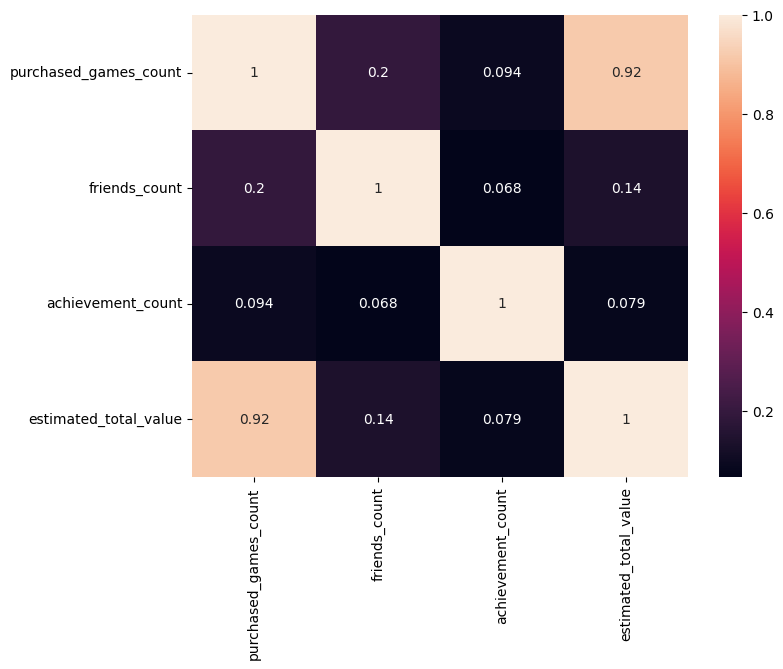

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = active_players[[
    "purchased_games_count",
    "friends_count",
    "achievement_count",
    "estimated_total_value"
]].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True)
plt.show()